# Модель оттока: бейзлайны и LightGBM

Задача: для клиента, у которого подписка заканчивается в месяце M, оценить вероятность того, что он не продлит её (отток по официальной разметке KKBox).
Признаки собраны в `scripts/05_churn_features.py` на первый день месяца M и не используют данные позже этой даты.

**Схема проверки.**
- Обучение: февраль 2017 (клиенты, у которых подписка заканчивается в феврале). Внутри февраля 20% клиентов отложено для подбора параметров и ранней остановки (`valid`).
- Тест: март 2017. Он используется один раз, для итоговой оценки, и в подборе параметров не участвует.
- Доля оттока в марте (9,0%) выше, чем в феврале (6,4%): модель сталкивается со сдвигом распределения. Это учитывается при анализе калибровки.

**Метрики.**
- `logloss`: основная метрика соревнования, оценивает качество вероятностей, в том числе калибровку.
- `PR-AUC` (средняя точность): качество ранжирования при редком классе; случайная модель даёт значение, равное доле оттока.
- `ROC-AUC`: для справки.
- Среднее предсказание против фактической доли оттока: простая проверка калибровки.

**Модели.** Константа (доля оттока в обучении), доля оттока по сегменту, логистическая регрессия и LightGBM. Все запуски фиксируются в MLflow (эксперимент `churn_model`).

In [1]:
import hashlib

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, precision_recall_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

FEATURES_FILE = "/workspace/data/processed/churn_features.parquet"
TRAIN_MONTH, TEST_MONTH = "2017-02-01", "2017-03-01"
RARE_MIN = 1000  # категории с меньшим числом клиентов в обучении объединяются в «other»
SEED = 42
INK, BLUE, ORANGE, GREEN, GRAY = "#2b2f36", "#0072B2", "#E69F00", "#009E73", "#8a8f98"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

NUM = [
    "last_plan_days", "last_list_price", "last_paid", "last_auto_renew", "last_is_cancel", "last_discount",
    "days_to_expire", "days_since_last_tx", "tenure_days", "n_tx", "n_cancel", "share_cancel", "n_paid_tx",
    "total_paid", "avg_paid", "share_zero_paid", "share_discount", "share_auto_renew", "n_plans", "n_methods",
    "n_tx_30d", "n_tx_90d", "n_plan_changes", "n_method_changes", "n_lapses", "has_profile", "age", "reg_tenure_days",
]
CAT = ["last_method", "city", "gender", "registered_via"]

con = duckdb.connect()
df = con.sql(f'''
    SELECT *
    FROM '{FEATURES_FILE}'
''').df()
df["expire_month"] = df["expire_month"].dt.strftime("%Y-%m-%d")
print(df.groupby("expire_month").agg(клиентов=("msno", "size"), доля_оттока=("is_churn", "mean")).round(4))

              клиентов  доля_оттока
expire_month                       
2017-02-01      992931       0.0639
2017-03-01      970960       0.0899


## 1. Разбиение и подготовка признаков
Разбиение: февраль делится на `fit` (80%, на нём обучаются модели и все преобразования) и `valid` (20%, подбор параметров и ранняя остановка),
март это `test`. Все преобразования обучаются только на `fit`:
- числовые признаки обрезаются по квантилям 0,1% и 99,9% (в данных есть даты окончания подписки вроде 1970 года);
- категориальные значения с числом клиентов меньше `RARE_MIN` заменяются на «other», пропуск на «missing»; значения, которых не было в `fit`, тоже считаются «other».

In [2]:
y = df["is_churn"].to_numpy()
is_train = (df["expire_month"] == TRAIN_MONTH).to_numpy()
idx_train = np.flatnonzero(is_train)
idx_fit, idx_valid = train_test_split(idx_train, test_size=0.2, stratify=y[idx_train], random_state=SEED)
idx_test = np.flatnonzero(~is_train)
print({"fit": len(idx_fit), "valid": len(idx_valid), "test": len(idx_test)})

lo = df.loc[idx_fit, NUM].quantile(0.001)
hi = df.loc[idx_fit, NUM].quantile(0.999)
frequent = {}
for c in CAT:
    counts = df.loc[idx_fit, c].astype("string").fillna("missing").value_counts()
    frequent[c] = set(counts[counts >= RARE_MIN].index) | {"missing"}


def prepare(frame: pd.DataFrame) -> pd.DataFrame:
    '''Применяет к признакам преобразования, обученные на `fit`.

    Args:
        frame (pd.DataFrame): строки таблицы признаков.

    Returns:
        pd.DataFrame: числовые признаки (обрезанные) и категориальные (строки с объединёнными редкими значениями).
    '''
    out = frame[NUM].astype(float).clip(lower=lo, upper=hi, axis=1)
    for c in CAT:
        s = frame[c].astype("string").fillna("missing")
        out[c] = s.where(s.isin(frequent[c]), "other")
    return out


X = prepare(df)
X_cat = X.copy()
for c in CAT:
    X_cat[c] = pd.Categorical(X[c], categories=sorted(frequent[c] | {"other"}))
for c in CAT:
    print(c, X.loc[idx_fit, c].value_counts().head(6).to_dict())

{'fit': 794344, 'valid': 198587, 'test': 970960}


last_method {'41': 455608, '40': 60844, '36': 54043, '39': 52452, '38': 50216, '37': 30767}


city {'1': 364352, 'missing': 92616, '13': 78642, '5': 56896, '4': 38371, '15': 34643}


gender {'missing': 480995, 'male': 164866, 'female': 148483}


registered_via {'7': 386230, '9': 189104, 'missing': 92616, '3': 84359, '4': 39576, '13': 2459}


## 2. Метрики и журнал MLflow
Функция `evaluate` считает четыре метрики для набора предсказаний. Функция `log_run` записывает запуск в MLflow: параметры, метрики, версию данных
(контрольная сумма файла признаков), список признаков, при необходимости модель и графики. Параметры подбираются только по `valid`; метрики на `test` записываются
для выбранной модели и для бейзлайнов, которые не настраиваются.

In [3]:
mlflow.set_tracking_uri("http://mlflow:5000")
EXPERIMENT = "churn_model"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location="mlflow-artifacts:/churn_model")
mlflow.set_experiment(EXPERIMENT)


def file_sha256(path: str) -> str:
    '''Считает контрольную сумму файла.

    Args:
        path (str): путь к файлу.

    Returns:
        str: SHA-256 в шестнадцатеричном виде.
    '''
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


DATA_HASH = file_sha256(FEATURES_FILE)


def evaluate(y_true: np.ndarray, p: np.ndarray) -> dict:
    '''Считает метрики качества вероятностей оттока.

    Args:
        y_true (np.ndarray): фактические метки (1: отток).
        p (np.ndarray): предсказанные вероятности оттока.

    Returns:
        dict: logloss, pr_auc, roc_auc, среднее предсказание и фактическая доля оттока.
    '''
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {
        "logloss": log_loss(y_true, p),
        "pr_auc": average_precision_score(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "mean_pred": float(p.mean()),
        "actual_rate": float(y_true.mean()),
    }


def log_run(name: str, params: dict, metrics: dict, model=None, figures: dict | None = None, tags: dict | None = None) -> None:
    '''Записывает запуск в MLflow.

    Args:
        name (str): название запуска.
        params (dict): параметры модели.
        metrics (dict): метрики (имя: значение).
        model: обученный LGBMClassifier (опционально).
        figures (dict | None): графики, имя файла: фигура matplotlib.
        tags (dict | None): теги запуска.
    '''
    with mlflow.start_run(run_name=name):
        mlflow.log_params(params)
        mlflow.log_param("data_sha256", DATA_HASH[:16])
        mlflow.log_metrics(metrics)
        mlflow.set_tags(tags or {})
        mlflow.log_dict({"num": NUM, "cat": CAT}, "features.json")
        if model is not None:
            mlflow.lightgbm.log_model(model, name="model")
        for fname, fig in (figures or {}).items():
            mlflow.log_figure(fig, fname)


results = {}  # название модели: {"valid": метрики, "test": метрики}


def register(name: str, p_valid: np.ndarray, p_test: np.ndarray) -> dict:
    '''Считает метрики на valid и test, сохраняет их в `results` и возвращает в виде плоского словаря для MLflow.

    Args:
        name (str): название модели.
        p_valid (np.ndarray): предсказания на valid.
        p_test (np.ndarray): предсказания на test.

    Returns:
        dict: метрики с префиксами valid_ и test_.
    '''
    results[name] = {"valid": evaluate(y[idx_valid], p_valid), "test": evaluate(y[idx_test], p_test)}
    return {f"{s}_{k}": v for s, m in results[name].items() for k, v in m.items()}

## 3. Бейзлайны
1. **Константа:** предсказывается доля оттока в `fit`. Это нижняя граница по logloss, у неё нет способности ранжировать (PR-AUC равен доле оттока, ROC-AUC 0,5).
2. **Сегмент:** клиенты делятся на сегменты по группе длины тарифа, автопродлению и числу дней до окончания подписки; для сегмента предсказывается сглаженная
   доля оттока в `fit` `(отток + m · общая доля) / (клиентов + m)`, m = 50. Значения, которых в `fit` нет, получают общую долю.
3. **Логистическая регрессия:** признаки стандартизируются, пропуски заполняются медианой с индикаторами пропусков, категории кодируются индикаторами.

In [4]:
base_rate = float(y[idx_fit].mean())
p_const = np.full(len(df), base_rate)
metrics = register("константа", p_const[idx_valid], p_const[idx_test])
log_run("baseline_constant", {"model": "constant", "rate": round(base_rate, 4)}, metrics, tags={"stage": "baseline"})


def plan_group(days: float) -> str:
    '''Относит длину тарифа последней транзакции к группе.

    Args:
        days (float): длина тарифа в днях.

    Returns:
        str: название группы.
    '''
    if pd.isna(days):
        return "нет"
    if days < 30:
        return "до 29 дней"
    if days <= 31:
        return "30-31 день"
    if days < 180:
        return "32-179 дней"
    return "180+ дней"


def expire_group(days: float) -> str:
    '''Относит число дней до окончания подписки к группе.

    Args:
        days (float): дней от начала месяца до окончания подписки.

    Returns:
        str: название группы.
    '''
    if pd.isna(days):
        return "нет"
    if days < 0:
        return "раньше месяца"
    if days <= 10:
        return "0-10"
    if days <= 20:
        return "11-20"
    if days <= 30:
        return "21-30"
    return "позже месяца"


seg = (
    df["last_plan_days"].map(plan_group) + "|" + df["last_auto_renew"].astype("string").fillna("нет")
    + "|" + df["days_to_expire"].map(expire_group)
)
M = 50
stat = pd.DataFrame({"seg": seg.iloc[idx_fit].values, "y": y[idx_fit]}).groupby("seg")["y"].agg(["sum", "count"])
rate = (stat["sum"] + M * base_rate) / (stat["count"] + M)
p_seg = seg.map(rate).fillna(base_rate).to_numpy()
metrics = register("сегмент", p_seg[idx_valid], p_seg[idx_test])
log_run("baseline_segment", {"model": "segment", "smoothing_m": M, "n_segments": len(rate)}, metrics, tags={"stage": "baseline"})

num_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())])
lr = Pipeline([
    ("prep", ColumnTransformer([
        ("num", num_pipe, NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ])),
    ("clf", LogisticRegression(C=1.0, max_iter=500)),
])
lr.fit(X.iloc[idx_fit], y[idx_fit])
p_lr = lr.predict_proba(X)[:, 1]
metrics = register("логистическая регрессия", p_lr[idx_valid], p_lr[idx_test])
log_run("baseline_logreg", {"model": "logreg", "C": 1.0}, metrics, tags={"stage": "baseline"})

pd.DataFrame({m: {f"{s} {k}": round(v, 4) for s, mm in r.items() for k, v in mm.items()} for m, r in results.items()}).T

2026/10/27 11:57:13 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/27 11:57:13 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/27 11:57:13 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



🏃 View run baseline_constant at: http://mlflow:5000/#/experiments/1/runs/2305ccdc074848c48ad0051250fda1aa
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run baseline_segment at: http://mlflow:5000/#/experiments/1/runs/dadfea7c0b9a49d988463111252aacb9
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run baseline_logreg at: http://mlflow:5000/#/experiments/1/runs/43f227953bdc4767836d6c3c0ffed24b
🧪 View experiment at: http://mlflow:5000/#/experiments/1


,valid logloss,valid pr_auc,valid roc_auc,valid mean_pred,valid actual_rate,test logloss,test pr_auc,test roc_auc,test mean_pred,test actual_rate
константа,0.2376,0.0639,0.5000,0.0639,0.0639,0.3075,0.0899,0.5000,0.0639,0.0899
сегмент,0.1743,0.3818,0.8077,0.0635,0.0639,0.2283,0.4862,0.8280,0.0655,0.0899
логистическая регрессия,0.1608,0.4687,0.8536,0.0640,0.0639,0.2156,0.5389,0.8357,0.0648,0.0899


## 4. LightGBM
Градиентный бустинг по деревьям. Категориальные признаки передаются как категории, пропуски числовых модель обрабатывает сама.
Классы не взвешиваются: нужны калиброванные вероятности, а не только порядок. Скорость обучения 0,05, число деревьев определяется ранней остановкой
по logloss на `valid` (50 итераций без улучшения). Небольшая сетка по размеру деревьев и минимальному числу клиентов в листе; для каждой конфигурации в MLflow
записываются только метрики на `valid`, лучшая по `valid` оценивается на `test`.

In [5]:
grid = [
    {"num_leaves": 31, "min_child_samples": 100},
    {"num_leaves": 63, "min_child_samples": 100},
    {"num_leaves": 31, "min_child_samples": 500},
    {"num_leaves": 63, "min_child_samples": 500},
]
BASE_PARAMS = {
    "n_estimators": 2000, "learning_rate": 0.05, "subsample": 0.8, "subsample_freq": 1,
    "colsample_bytree": 0.8, "reg_lambda": 1.0, "random_state": SEED, "n_jobs": 2, "verbose": -1,
}

fits = []
for params in grid:
    clf = lgb.LGBMClassifier(**BASE_PARAMS, **params)
    clf.fit(
        X_cat.iloc[idx_fit], y[idx_fit],
        eval_set=[(X_cat.iloc[idx_valid], y[idx_valid])], eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    p_v = clf.predict_proba(X_cat.iloc[idx_valid])[:, 1]
    m = evaluate(y[idx_valid], p_v)
    fits.append((m["logloss"], params, clf))
    log_run(
        f"lgbm_grid_{params['num_leaves']}_{params['min_child_samples']}",
        {**params, "best_iteration": clf.best_iteration_},
        {f"valid_{k}": v for k, v in m.items()},
        tags={"stage": "grid"},
    )
    print(params, "деревьев:", clf.best_iteration_, "valid logloss:", round(m["logloss"], 5), "PR-AUC:", round(m["pr_auc"], 4))

best_loss, best_params, best_clf = min(fits, key=lambda t: t[0])
print("лучшая конфигурация:", best_params)

🏃 View run lgbm_grid_31_100 at: http://mlflow:5000/#/experiments/1/runs/abe7b0ecbfcc46b696f09adb1f8a9c1d
🧪 View experiment at: http://mlflow:5000/#/experiments/1
{'num_leaves': 31, 'min_child_samples': 100} деревьев: 568 valid logloss: 0.14459 PR-AUC: 0.5784


🏃 View run lgbm_grid_63_100 at: http://mlflow:5000/#/experiments/1/runs/c86ab4724b9b4e4fb77ae2955fbe9993
🧪 View experiment at: http://mlflow:5000/#/experiments/1
{'num_leaves': 63, 'min_child_samples': 100} деревьев: 368 valid logloss: 0.14444 PR-AUC: 0.5791


🏃 View run lgbm_grid_31_500 at: http://mlflow:5000/#/experiments/1/runs/a2d34f53873145fc87d018411900997b
🧪 View experiment at: http://mlflow:5000/#/experiments/1
{'num_leaves': 31, 'min_child_samples': 500} деревьев: 597 valid logloss: 0.1448 PR-AUC: 0.5769


🏃 View run lgbm_grid_63_500 at: http://mlflow:5000/#/experiments/1/runs/44616f3a637e429bb83911aa7de97ea6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
{'num_leaves': 63, 'min_child_samples': 500} деревьев: 352 valid logloss: 0.14471 PR-AUC: 0.5772
лучшая конфигурация: {'num_leaves': 63, 'min_child_samples': 100}


In [6]:
p_lgb = best_clf.predict_proba(X_cat)[:, 1]
metrics = register("LightGBM", p_lgb[idx_valid], p_lgb[idx_test])
table = pd.DataFrame({m: {f"{s} {k}": round(v, 4) for s, mm in r.items() for k, v in mm.items()} for m, r in results.items()}).T
table

,valid logloss,valid pr_auc,valid roc_auc,valid mean_pred,valid actual_rate,test logloss,test pr_auc,test roc_auc,test mean_pred,test actual_rate
константа,0.2376,0.0639,0.5000,0.0639,0.0639,0.3075,0.0899,0.5000,0.0639,0.0899
сегмент,0.1743,0.3818,0.8077,0.0635,0.0639,0.2283,0.4862,0.8280,0.0655,0.0899
логистическая регрессия,0.1608,0.4687,0.8536,0.0640,0.0639,0.2156,0.5389,0.8357,0.0648,0.0899
LightGBM,0.1444,0.5791,0.8975,0.0639,0.0639,0.2059,0.5891,0.8608,0.0639,0.0899


## 5. Качество на тесте (март)
Основные метрики на тесте для всех моделей. Для PR-AUC ориентир это доля оттока в марте (случайная модель); для logloss ориентир это константа.

In [7]:
summary = pd.DataFrame({
    m: {
        "logloss": r["test"]["logloss"], "PR-AUC": r["test"]["pr_auc"], "ROC-AUC": r["test"]["roc_auc"],
        "среднее предсказание": r["test"]["mean_pred"], "факт. доля оттока": r["test"]["actual_rate"],
    }
    for m, r in results.items()
}).T.round(4)
summary

,logloss,PR-AUC,ROC-AUC,среднее предсказание,факт. доля оттока
константа,0.3075,0.0899,0.5000,0.0639,0.0899
сегмент,0.2283,0.4862,0.8280,0.0655,0.0899
логистическая регрессия,0.2156,0.5389,0.8357,0.0648,0.0899
LightGBM,0.2059,0.5891,0.8608,0.0639,0.0899


## 6. Калибровка и сдвиг доли оттока
Кривая надёжности: клиенты тестового месяца делятся на группы по предсказанной вероятности (децили), сравниваются средняя предсказанная вероятность и фактическая доля оттока.
Идеальная калибровка лежит на диагонали. Доля оттока в марте выше февральской, поэтому ожидается систематическое занижение вероятностей.

Диагностика сдвига: если известна доля оттока нового месяца, логиты предсказаний можно сдвинуть на константу так, чтобы средняя вероятность совпала с ней.
Это справочный расчёт (он использует долю оттока марта и недоступен в момент прогноза); он показывает, какая часть потерь logloss связана со сдвигом, а не с ранжированием.

LightGBM на тесте: logloss 0.2059 -> после сдвига на долю оттока марта 0.1979


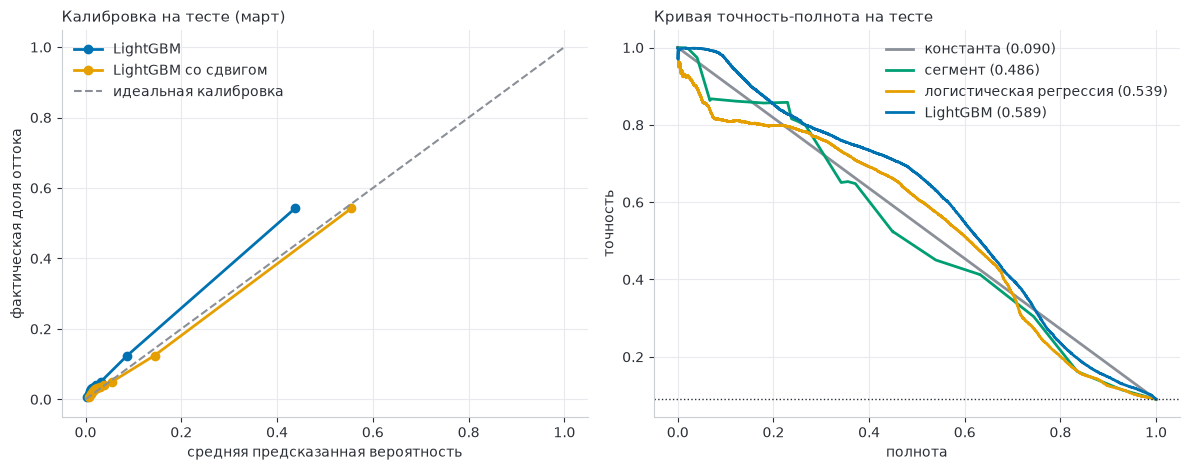

In [8]:
def shift_to_rate(p: np.ndarray, target: float) -> np.ndarray:
    '''Сдвигает логиты предсказаний на константу так, чтобы средняя вероятность равнялась `target`.

    Args:
        p (np.ndarray): предсказанные вероятности.
        target (float): целевая средняя вероятность.

    Returns:
        np.ndarray: вероятности после сдвига.
    '''
    z = logit(np.clip(p, 1e-6, 1 - 1e-6))
    b = brentq(lambda s: expit(z + s).mean() - target, -5, 5)
    return expit(z + b)


y_test = y[idx_test]
p_test = p_lgb[idx_test]
p_shift = shift_to_rate(p_test, y_test.mean())
print("LightGBM на тесте: logloss", round(evaluate(y_test, p_test)["logloss"], 4),
      "-> после сдвига на долю оттока марта", round(evaluate(y_test, p_shift)["logloss"], 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
for p, label, color in [(p_test, "LightGBM", BLUE), (p_shift, "LightGBM со сдвигом", ORANGE)]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", color=color, lw=2, label=label)
top = max(0.5, float(p_test.max()))
ax.plot([0, top], [0, top], color=GRAY, ls="--", label="идеальная калибровка")
ax.set_xlabel("средняя предсказанная вероятность")
ax.set_ylabel("фактическая доля оттока")
ax.set_title("Калибровка на тесте (март)", loc="left", fontsize=11)
ax.legend(frameon=False)

ax = axes[1]
for name, p, color in [("константа", p_const, GRAY), ("сегмент", p_seg, GREEN), ("логистическая регрессия", p_lr, ORANGE), ("LightGBM", p_lgb, BLUE)]:
    prec, rec, _ = precision_recall_curve(y_test, p[idx_test])
    ax.plot(rec, prec, color=color, lw=2, label=f"{name} ({average_precision_score(y_test, p[idx_test]):.3f})")
ax.axhline(y_test.mean(), color=INK, lw=1, ls=":")
ax.set_xlabel("полнота")
ax.set_ylabel("точность")
ax.set_title("Кривая точность-полнота на тесте", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.tight_layout()
fig_cal = fig
plt.show()

## 7. Важность признаков (LightGBM)
Встроенная важность: суммарный прирост качества (gain), который дают разбиения по признаку. Показатель говорит, какие признаки модель использует сильнее всего,
но не направление связи и не причинный эффект. Коррелирующие признаки делят важность между собой.

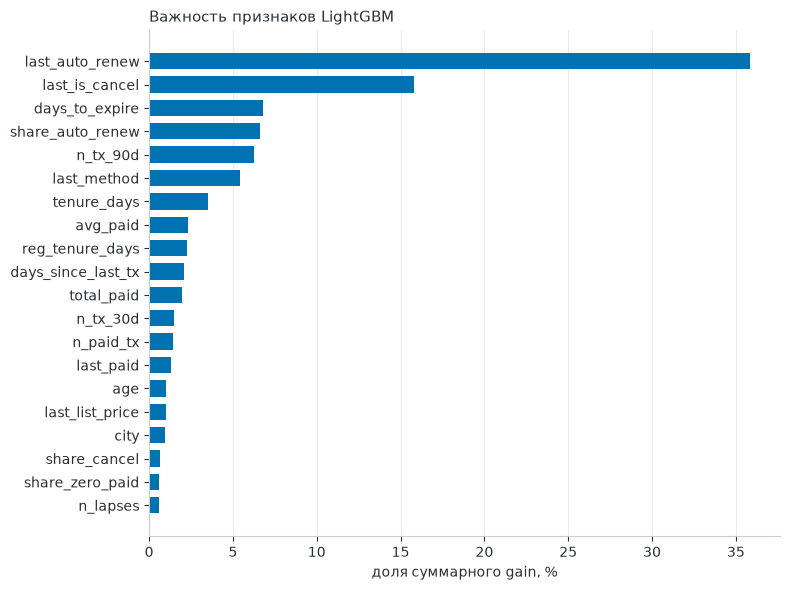

,"доля gain, %"
last_auto_renew,35.84
last_is_cancel,15.79
days_to_expire,6.79
share_auto_renew,6.59
n_tx_90d,6.23
last_method,5.40
tenure_days,3.51
avg_paid,2.33
reg_tenure_days,2.25
days_since_last_tx,2.07


In [9]:
imp = pd.Series(
    best_clf.booster_.feature_importance(importance_type="gain"), index=best_clf.booster_.feature_name()
).sort_values(ascending=False)
imp_share = (100 * imp / imp.sum()).round(2)
top = imp_share.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
ax.set_xlabel("доля суммарного gain, %")
ax.set_title("Важность признаков LightGBM", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout()
fig_imp = fig
plt.show()
imp_share.head(15).to_frame("доля gain, %")

## 8. Срезы на тесте
Те же метрики LightGBM по группам, выделенным в анализе выживаемости: с автопродлением и без, с профилем и без. Это проверяет, что качество не держится на одной группе.

In [10]:
test_df = df.iloc[idx_test].assign(p=p_test)
rows = {}
for name, mask in [
    ("автопродление", test_df.last_auto_renew == 1),
    ("без автопродления", test_df.last_auto_renew == 0),
    ("есть профиль", test_df.has_profile == 1),
    ("нет профиля", test_df.has_profile == 0),
]:
    g = test_df[mask]
    m = evaluate(g.is_churn.to_numpy(), g.p.to_numpy())
    rows[name] = {"клиентов": len(g), "доля оттока": g.is_churn.mean(), "среднее предсказание": m["mean_pred"],
                  "logloss": m["logloss"], "PR-AUC": m["pr_auc"], "ROC-AUC": m["roc_auc"]}
pd.DataFrame(rows).T.round(4)

,клиентов,доля оттока,среднее предсказание,logloss,PR-AUC,ROC-AUC
автопродление,854162.0,0.0453,0.0281,0.1557,0.3412,0.7499
без автопродления,114274.0,0.4136,0.3250,0.5701,0.7302,0.7804
есть профиль,860967.0,0.0946,0.0662,0.2141,0.5916,0.8630
нет профиля,109993.0,0.0535,0.0457,0.1417,0.5286,0.8161


## 9. Запись итоговой модели в MLflow
Запуск `lgbm_best` содержит параметры, метрики на `valid` и `test`, модель, список признаков и графики калибровки и важности.

In [11]:
metrics = {f"{s}_{k}": v for s, m in results["LightGBM"].items() for k, v in m.items()}
log_run(
    "lgbm_best",
    {**best_params, "best_iteration": best_clf.best_iteration_, "learning_rate": BASE_PARAMS["learning_rate"]},
    metrics,
    model=best_clf,
    figures={"calibration_pr.png": fig_cal, "feature_importance.png": fig_imp},
    tags={"stage": "final"},
)
print("записано в MLflow, интерфейс: http://localhost:5001")

🏃 View run lgbm_best at: http://mlflow:5000/#/experiments/1/runs/f044231c4a0d4bd89d6576f56b4eca31
🧪 View experiment at: http://mlflow:5000/#/experiments/1
записано в MLflow, интерфейс: http://localhost:5001


## 10. Сохранение предсказаний
Предсказания лучшей модели для тестового месяца (март) сохраняются в `data/processed/churn_predictions.parquet`: они используются в `08_retention_value.ipynb`.
Модель не обучалась на мартовских клиентах, поэтому предсказания честные. Для сдвига логитов к фактической доле оттока марта (справочный расчёт) сохраняется и
второй столбец.

In [12]:
pred = pd.DataFrame({
    "msno": df["msno"].to_numpy()[idx_test],
    "expire_month": df["expire_month"].to_numpy()[idx_test],
    "is_churn": y_test,
    "p_lgbm": p_test,
    "p_lgbm_shifted": p_shift,
})
pred.to_parquet("/workspace/data/processed/churn_predictions.parquet", index=False)
print("сохранено строк:", len(pred), " средние p, p со сдвигом, факт:", pred[["p_lgbm", "p_lgbm_shifted", "is_churn"]].mean().round(4).to_dict())

сохранено строк: 970960  средние p, p со сдвигом, факт: {'p_lgbm': 0.0639, 'p_lgbm_shifted': 0.0899, 'is_churn': 0.0899}


## Выводы
- **Сравнение моделей на тесте (март).** LightGBM даёт logloss 0,206 против 0,308 у константы, 0,228 у сегментов и 0,216 у логистической регрессии; PR-AUC 0,589 (случайная модель: 0,090), ROC-AUC 0,861. Бустинг лучше простых моделей по всем метрикам, но выигрыш у логистической регрессии умеренный: logloss ниже на 0,010, PR-AUC выше на 0,05.
- **Различие между valid и test.** На отложенных клиентах февраля LightGBM показывает logloss 0,144 и ROC-AUC 0,898, на марте 0,206 и 0,861. Оценка внутри месяца оптимистична: клиенты февраля обучающей и отложенной частей одного периода, а март отличается и долей оттока, и поведением. Итоговой оценкой считается тест.
- **Калибровка.** Среднее предсказание на марте 6,4% при фактической доле оттока 9,0%: модель занижает вероятности, она унаследовала долю оттока февраля (6,4%). Сдвиг логитов на долю марта снижает logloss с 0,206 до 0,198, то есть сдвиг объясняет лишь небольшую часть ухудшения (около 0,008 из 0,06). Основная часть связана с потерей качества ранжирования на новом месяце.
- **Важность признаков.** Суммарный gain: автопродление в последней транзакции 35,8%, признак отмены в последней транзакции 15,8%, дни до окончания подписки 6,8%, доля транзакций с автопродлением 6,6%, число транзакций за 90 дней 6,2%, способ оплаты 5,4%. Это согласуется с анализом выживаемости (автопродление, способ оплаты).
- **Срезы.** Клиенты без автопродления: фактический отток 41,4%, среднее предсказание 32,5%, ROC-AUC 0,78; с автопродлением: 4,5% и 2,8%, ROC-AUC 0,75. Занижение есть во всех срезах. Качество по клиентам без профиля ниже по ROC-AUC (0,816 против 0,863).
- **Ограничения.** Логи прослушивания не использовались; SHAP не считался; прямое сравнение с результатами соревнования некорректно, потому что набор клиентов и разметка здесь не совпадают с оценочными данными Kaggle. Дальнейшее улучшение: признаки из логов (этап 5), учёт сдвига между месяцами при обучении.
